# Face Recognition Data: Loading and Exploratory Data Analysis

**COS30082 Applied Machine Learning** · Swinburne University of Technology
**Group project:** Facial Recognition with Emotion and Liveness
**Notebook:** `Backend-Core/training/Face_Recognition.ipynb`

---

# Introduction

## Course introduction

This notebook belongs to the group project of **COS30082 Applied Machine Learning**. The project builds a camera-based attendance system with three models:

| Model | Question it answers | Data |
|---|---|---|
| Face recognition (verification) | Who is this person? | `Face Recognition` data (this notebook) |
| Emotion recognition | How does the face look? | `Emotion Detection` data |
| Liveness (anti-spoofing) | Is this a real, live face? | `Anti-Spoofing` data |

The assignment requires **two** training methods for face verification: a **classification-based** CNN (softmax over known identities) and a **metric-learning** CNN (embeddings trained with pair or triplet loss). Both methods use the data prepared here, so this notebook documents how the data is loaded, labelled and checked before any model is trained.

**Group members:** Le Xuan Ny, Pahan Pathirathna, Nguyen Quang Khai, Pham Dinh Duc Anh, Pham Nguyen Minh Hoang, Truong Ngoc Gia Hieu. The original EDA (Task 20) was written by Pham Dinh Duc Anh and restructured for the team.

## About this file

**Purpose.** Load the face recognition dataset from Google Drive, assign labels, and audit its quality so the team can decide the cleaning and splitting rules before training.

**What it does not do.** It trains no model, changes no data on Drive and identifies no real person. Head pose and expression are estimated from facial landmarks only.

**Questions the EDA answers**

1. How many identities and images are there, and how many images does each identity have (min, max, average)?
2. What are the image sizes, formats and colour modes, and are any files corrupted, duplicated, low-resolution or blurry?
3. How well are lighting, pose and expression covered, and is any group over- or under-represented?
4. Do people or identical images overlap between train, validation, test and verification (data leakage)?
5. Are the verification images free of leakage against the training data?
6. Are the results saved and summarised so the team can act on them?

## How this notebook is organised

- **Every code cell does exactly one job** (one import block, one check, one `def`, one table, one chart) and its first line is a comment such as `# CELL 7: Configuration: outputs`. Comments inside the code explain each step.
- **Every code cell is followed by an explanation cell** with the same number. It says what the cell does, what goes in and out, what to check in the result and what to look at first if the cell fails.
- Cells depend on the ones above them, so run them **from top to bottom**. If a cell fails, fix it and run it again before moving on.
- All settings (paths, thresholds, sample sizes) are in the configuration cells near the top, so nobody needs to edit code further down.

## Notebook structure

| Part | Section | Content |
|---|---|---|
| Introduction | Setup and configuration | Packages, libraries, Google Drive, settings, helper functions |
| **Part A** Data Loading and Assigning | 1.1 Classification | Locate the data, list every image, assign an identity and a numeric class label |
| | 1.2 Verification | List and count the verification images (flat folder, no sub-folders) |
| **Part B** EDA | 2.1 Classification | Images per identity, size and quality, duplicates, lighting and pose, balance, leakage between splits |
| | 2.2 Verification | Verification image quality, leakage against training, visual checks |
| | 2.3 Summary and handoff | Written summary, HTML report, copy of all outputs to Google Drive |

## Dataset at a glance

Course-provided face dataset, shared as the Google Drive folder `Face Recognition`:

```
Face Recognition/
├── classification_data/
│   ├── train_data/<identity>/*.jpg     closed-set training images
│   ├── val_data/<identity>/*.jpg       validation images (same identities as train)
│   └── test_data/<identity>/*.jpg      test images (same identities as train)
└── verification_data/*.jpg             flat folder of verification images (no sub-folders)
```

Reference figures from the first run on 3 November 2026 (your run will print its own numbers):
465,735 images in total (train 380,638, val 8,000, test 8,000, verification 69,097), 4,000 identities, all 64x64 JPEG RGB, no corrupted files, 2 images per identity in val and test.

## How to run in Google Colab

1. Upload this notebook to Colab and choose **Runtime, Change runtime type, CPU** (a GPU is not needed).
2. In Google Drive, open the shared **Face Recognition** folder and choose **Organize, Add shortcut, My Drive**.
3. Run the cells from top to bottom. Allow access to Google Drive when asked.
4. Reading hundreds of thousands of small files directly from Drive is slow. If a `.zip` of the dataset is in your My Drive, the notebook copies it to the Colab disk and unzips it there (fast). Otherwise it reads from Drive and scans a 10% sample by default; change `SCAN_FRACTION` in the analysis-settings cell to scan everything.
5. All tables, charts and reports are written to `eda_outputs/` and copied to `My Drive/face_recognition_eda/`.

Before committing this notebook to GitHub, clear all outputs (Edit, Clear all outputs).

## Setup and configuration

In [1]:
# CELL 1: Install packages
# Install the two packages Colab does not ship with (-q = quiet output)
%pip -q install imagehash mediapipe

**Explanation of Cell 1: Install packages**

- **Purpose:** install packages that Colab does not have by default.
- **`imagehash`**: perceptual hash of an image (a short fingerprint that survives resizing and re-saving), used to find near-duplicate images.
- **`mediapipe`**: Google's face-landmark model, used only in the head-pose cells.
- **Output:** nothing visible. A red pip warning about versions is normal.
- **If it fails:** check the Colab internet connection and run again. If a later `import imagehash` fails, restart the runtime and run from Cell 1.

In [2]:
# CELL 2: Library loading
# --- standard library ---
import os, math, shutil, hashlib, base64, html, subprocess   # files, maths, copying, hashing, HTML, shell commands
from pathlib import Path                                      # safe file paths: Path('a') / 'b'
from concurrent.futures import ThreadPoolExecutor             # read many images at the same time

# --- data and plotting ---
import numpy as np                  # arrays and statistics
import pandas as pd                 # tables (DataFrame)
import matplotlib.pyplot as plt     # charts and image grids

# --- images ---
import cv2                          # OpenCV: sharpness (Laplacian) and resizing
from PIL import Image               # open images, read size / format / colour mode
import imagehash                    # perceptual hash (near-duplicate detection)

# --- display helpers ---
from tqdm.auto import tqdm          # progress bars
from IPython.display import display # show a table inside a cell that also plots or prints

**Explanation of Cell 2: Library loading**

- **Purpose:** import every library in one place, so a missing library is found immediately. Nothing else happens in this cell.
- **Output:** nothing printed when it works.

| Library | What we use it for |
|---|---|
| `os` | list files and folders (`os.scandir`), read environment variables |
| `math` | grid sizes (`ceil`) and head-pose angles |
| `shutil` | copy files (dataset zip, output files to Drive) |
| `hashlib` | MD5 hash of the file bytes: identical files give identical hashes |
| `base64`, `html` | build the single-file HTML report |
| `subprocess` | run the `unzip` command |
| `pathlib.Path` | build file paths |
| `ThreadPoolExecutor` | read many images in parallel |
| `numpy`, `pandas` | numbers and tables |
| `matplotlib.pyplot` | charts and image grids |
| `cv2` | sharpness measure and resizing |
| `PIL.Image` | open images |
| `imagehash` | perceptual hash |
| `tqdm` | progress bars |
| `display` | show tables |

- **If it fails:** `ModuleNotFoundError` means Cell 1 was not run. Run Cell 1, restart the runtime, then run this cell.

In [3]:
# CELL 3: Google Drive connection
# Try to mount Google Drive (only works inside Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')   # a pop-up asks for permission
    IN_COLAB = True
except ImportError:
    IN_COLAB = False                # running on a laptop: no Drive

print('running in Colab:', IN_COLAB)

Mounted at /content/drive
running in Colab: True


**Explanation of Cell 3: Google Drive connection**

- **Purpose:** connect Google Drive to Colab so the dataset can be read and results saved.
- **In Colab:** allow access in the pop-up. Drive then appears at `/content/drive/MyDrive`.
- **Outside Colab:** the import fails, `IN_COLAB` is `False`, and local paths are used.
- **Variable created:** `IN_COLAB` (True / False).
- **If it fails:** allow pop-ups for colab.research.google.com. `Mounted at /content/drive` means success.

In [4]:
# CELL 4: Configuration: data location
DATA_FOLDER_NAME = 'Face Recognition'   # name of the shared folder (or of your shortcut to it) in My Drive
ZIP_PATH = None                         # full path of a dataset .zip, or None = search for one
USE_ZIP = 'auto'                        # 'auto' = use a zip if found | True = require one | False = never

**Explanation of Cell 4: Configuration: data location**

- **Purpose:** tell the notebook where the dataset is. Change values here only.
- **`DATA_FOLDER_NAME`**: folder name as shown in My Drive. If you renamed your shortcut, change it here.
- **`ZIP_PATH`**: `None` lets the notebook look for a `.zip`; or give a path like `'/content/drive/MyDrive/faces.zip'`.
- **`USE_ZIP`**: `'auto'` uses a zip when one exists; `True` stops with an error if none; `False` always reads Drive directly.
- **Output:** none.

In [5]:
# CELL 5: Configuration: dataset layout
# split name -> folder (relative to the dataset root)
SPLITS = {
    'train': 'classification_data/train_data',
    'val':   'classification_data/val_data',
    'test':  'classification_data/test_data',
}
VERIF_DIR = 'verification_data'                       # flat folder of verification images
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}  # file extensions counted as images

**Explanation of Cell 5: Configuration: dataset layout**

- **Purpose:** describe how the dataset folder is organised.
- **`SPLITS`**: split name to folder. The key becomes the `split` column in every table.
- **`VERIF_DIR`**: the flat folder of verification images.
- **`IMG_EXT`**: other files (for example `.txt`) are skipped and counted.
- **Output:** none. Change only if the folder structure changes.

In [6]:
# CELL 6: Configuration: analysis settings and thresholds
SEED = 42               # fixed random seed: same "random" samples on every run
SCAN_FRACTION = None    # share of images scanned: None = 1.0 with a zip, 0.1 from Drive
N_POSE_SAMPLE = 3000    # images used for the head-pose / expression estimate

# Starting thresholds, to be confirmed with the charts and grids in Part B
LOW_RES_PX = 32         # shortest side below this = low resolution
BLUR_THR = 50.0         # sharpness (Laplacian variance) below this = blurry
DARK, BRIGHT = 60, 190  # mean grey level below DARK = too dark, above BRIGHT = too bright
LOW_CONTRAST = 25       # grey-level std below this = low contrast

**Explanation of Cell 6: Configuration: analysis settings and thresholds**

- **Purpose:** keep every tunable number in one cell.
- **`SEED`**: makes samples repeatable between teammates.
- **`SCAN_FRACTION`**: share of images opened by the quality scans. `1.0` = all (slow from Drive), `0.1` = random 10%, `None` = decided automatically later.
- **`N_POSE_SAMPLE`**: pose and expression are slow, so only a sample is checked.
- **Thresholds** are *starting values*. Look at the charts and grids in Part B before using them to remove data.
- **Output:** none.

In [7]:
# CELL 7: Configuration: outputs
# Local output folder on the Colab disk (EDA_OUT env variable overrides it for local runs)
OUT = Path(os.environ.get('EDA_OUT', 'eda_outputs'))
OUT.mkdir(parents=True, exist_ok=True)

# Folder in My Drive where results are copied at the end (None outside Colab)
SAVE_TO = Path('/content/drive/MyDrive/face_recognition_eda') if IN_COLAB else None

np.random.seed(SEED)    # make numpy randomness repeatable
print('results are written to:', OUT.resolve())
print('copied to Drive at    :', SAVE_TO)

results are written to: /content/eda_outputs
copied to Drive at    : /content/drive/MyDrive/face_recognition_eda


**Explanation of Cell 7: Configuration: outputs**

- **Purpose:** decide where results are saved.
- **`OUT`**: local folder `eda_outputs/` (deleted when the Colab session ends).
- **`SAVE_TO`**: folder in My Drive; the last cell copies everything there so results survive.
- **Output:** two printed paths.

In [8]:
# CELL 8: Helper function: savefig
def savefig(name):
    plt.tight_layout()                                              # avoid overlapping labels
    plt.savefig(OUT / f'{name}.png', dpi=120, bbox_inches='tight')  # save the PNG
    plt.show()                                                      # then show it

**Explanation of Cell 8: Helper function: savefig**

- **Purpose:** save the current chart as a PNG in `OUT` and show it.
- **Argument:** `name`, file name without `.png`.
- **Used by:** every chart cell and `show_grid`. The PNGs are embedded in the HTML report.
- **Output:** none (defines the function only).

In [9]:
# CELL 9: Helper function: show_grid
def show_grid(paths, title, name, ncols=8, labels=None):
    paths = list(paths)
    if not paths:                                        # nothing to draw
        print(f'{title}: nothing to show')
        return
    # default caption = identity folder name
    labels = list(labels) if labels is not None else [Path(p).parent.name[:10] for p in paths]
    nrows = math.ceil(len(paths) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.4, nrows * 1.6), squeeze=False)
    for ax in axes.ravel():                              # hide all axes first
        ax.axis('off')
    for ax, p, lab in zip(axes.ravel(), paths, labels):
        try:
            ax.imshow(Image.open(p).convert('RGB'))      # draw the image
            ax.set_title(str(lab), fontsize=6)           # small caption
        except Exception:
            ax.set_title('unreadable', fontsize=6)       # a broken file must not stop the grid
    fig.suptitle(title)
    savefig(name)

**Explanation of Cell 9: Helper function: show_grid**

- **Purpose:** draw many images in a grid so a person can look at them (numbers cannot show a blurry or mislabelled face).
- **Arguments:** `paths`, `title`, `name` (PNG name), `ncols` (default 8), `labels` (caption under each image).
- **Behaviour:** unreadable images show the caption `unreadable`; an empty list prints "nothing to show".
- **Output:** none (defines the function only).

In [10]:
# CELL 10: Helper function: scan_image
def scan_image(path):
    """Measure ONE image and return a dictionary."""
    rec = {'path': path}
    try:
        raw = Path(path).read_bytes()
        rec['bytes'] = len(raw)
        rec['md5'] = hashlib.md5(raw).hexdigest()          # identical files -> identical hash
        with Image.open(path) as im:
            rec['format'], rec['mode'] = im.format, im.mode
            rec['width'], rec['height'] = im.size
            im.load()                                      # force full decode (detects truncated files)
            rgb = np.asarray(im.convert('RGB'), dtype=np.float32)
            rec['phash'] = str(imagehash.phash(im))        # perceptual hash (near copies)
        grey = rgb.mean(axis=2)
        rec['brightness'] = float(grey.mean())             # mean grey level
        rec['contrast'] = float(grey.std())                # spread of grey levels
        rec['blur'] = float(cv2.Laplacian(grey, cv2.CV_32F).var())   # low = blurry
        # an RGB file whose 3 channels are equal is really greyscale
        rec['is_grey'] = bool(np.abs(rgb[..., 0] - rgb[..., 1]).max() < 2
                              and np.abs(rgb[..., 1] - rgb[..., 2]).max() < 2)
        rec['corrupt'] = False
    except Exception as e:                                 # never stop the whole scan for one bad file
        rec['corrupt'] = True
        rec['error'] = f'{type(e).__name__}: {e}'[:120]
    return rec

**Explanation of Cell 10: Helper function: scan_image**

- **Purpose:** open **one** image and measure everything the EDA needs.

| Key | Meaning | Used for |
|---|---|---|
| `md5` | hash of the file bytes | identical-file duplicates, leakage |
| `phash` | perceptual hash | near duplicates |
| `format`, `mode`, `width`, `height` | file facts | size and format tables |
| `brightness`, `contrast` | grey-level mean / spread | lighting, low-contrast flag |
| `blur` | Laplacian variance (low = blurry) | blur flag |
| `is_grey` | all 3 channels equal | greyscale flag |
| `corrupt`, `error` | could not be read, and why | corrupted-file list |

- **Safety:** all errors are caught, so one broken file never stops the scan.
- **Output:** none (defines the function only).

In [11]:
# CELL 11: Helper function: scan_many
def scan_many(df, fraction, desc):
    # choose all images or a random sample
    part = df if fraction >= 1 else df.sample(frac=fraction, random_state=SEED)
    # measure them in parallel (16 threads; reading files mostly waits for the disk)
    with ThreadPoolExecutor(max_workers=16) as ex:
        recs = list(tqdm(ex.map(scan_image, part.path), total=len(part), desc=desc))
    # join the measurements back onto the original table (keeps split / identity columns)
    res = part.merge(pd.DataFrame(recs), on='path')
    if 'error' not in res:
        res['error'] = None
    res['short_side'] = res[['width', 'height']].min(axis=1)   # smaller side, for the low-res flag
    return res

**Explanation of Cell 11: Helper function: scan_many**

- **Purpose:** run `scan_image` on many images at once and return one table.
- **Arguments:** `df` (table with a `path` column), `fraction` (1.0 = all, 0.1 = random 10%), `desc` (progress-bar text).
- **Adds:** `short_side`, the smaller of width and height.
- **Output:** none (defines the function only).
- **Too slow?** lower `SCAN_FRACTION` in the analysis-settings cell.

In [12]:
# CELL 12: Helper function: fmt_int
def fmt_int(x):
    # 380638 -> '380,638'; missing values -> '0'
    return '0' if pd.isna(x) else f'{int(x):,}'

**Explanation of Cell 12: Helper function: fmt_int**

- **Purpose:** format numbers with thousands separators for the written summary. Missing values become `0`.
- **Output:** none (defines the function only).

---
# Part A: Data Loading and Assigning

Part A turns the folders on Google Drive into tables the rest of the project can use:

- **Classification** (1.1): one row per image with its split, identity and numeric **class label** (input of the softmax classifier).
- **Verification** (1.2): one row per verification image (a flat folder, so there are no identities or splits to assign).

Nothing is modified on Drive.

## 1.1 Classification

In [13]:
# CELL 13: Function: find_data_root
def find_data_root():
    # 1) explicit path from the environment (used for local runs)
    env = os.environ.get('FACE_DATA')
    if env and (Path(env) / 'classification_data').exists():
        return Path(env)
    # 2) the folder or shortcut directly in My Drive
    default = Path('/content/drive/MyDrive') / DATA_FOLDER_NAME
    if (default / 'classification_data').exists():
        return default
    # 3) search one or two levels below My Drive and in "shared with me" shortcut targets
    roots = [Path('/content/drive/MyDrive'), Path('/content/drive/.shortcut-targets-by-id')]
    for r in roots:
        for pat in (DATA_FOLDER_NAME, f'*/{DATA_FOLDER_NAME}', f'*/*/{DATA_FOLDER_NAME}'):
            for p in r.glob(pat):
                if (p / 'classification_data').exists():   # accept only the real dataset
                    return p
    return None

**Explanation of Cell 13: Function: find_data_root**

- **Purpose:** find the dataset folder wherever your shortcut ended up.
- **Search order:** `FACE_DATA` environment variable, then `My Drive/<DATA_FOLDER_NAME>`, then up to two levels below My Drive and the shared-shortcut folder.
- A folder is accepted only if it contains `classification_data`.
- **Returns:** a `Path`, or `None`.
- **Output:** none (defines the function only).

In [14]:
# CELL 14: Locate the dataset folder on Drive
# Run the search defined above
DATA_ROOT = find_data_root()
print('dataset folder on Drive:', DATA_ROOT)

dataset folder on Drive: /content/drive/MyDrive/Facial_Recognition_with_Emotion_and_Liveliness/Face Recognition


**Explanation of Cell 14: Locate the dataset folder on Drive**

- **Purpose:** call `find_data_root` and keep the result in `DATA_ROOT`.
- **Output:** the folder path, or `None` if nothing was found (the next cell decides whether that is an error).

In [15]:
# CELL 15: Check that the dataset exists
# Stop early, with a clear message, if the dataset cannot be reached
if DATA_ROOT is None and USE_ZIP is not True:
    raise FileNotFoundError(
        f'Could not find a folder named "{DATA_FOLDER_NAME}" containing classification_data. '
        'In Google Drive, right-click the shared folder, choose Organize, Add shortcut, My Drive, '
        'then run Cell 14 again (or set DATA_FOLDER_NAME / ZIP_PATH in Cell 4).')

# Show what is inside and whether each expected item is present
if DATA_ROOT is not None:
    expected = ['classification_data', 'verification_data']
    for item in expected:
        print(('OK      ' if (DATA_ROOT / item).exists() else 'MISSING ') + item)

OK      classification_data
OK      verification_data


**Explanation of Cell 15: Check that the dataset exists**

- **Purpose:** the existence check. It stops with a clear message when the dataset is not reachable, and lists which expected items are present.
- **Output:** one line per expected item, `OK` or `MISSING`.
- **If it raises `FileNotFoundError`** (the most common problem): in Google Drive right-click the shared **Face Recognition** folder, choose **Organize, Add shortcut, My Drive**, then run Cell 14 again. If your shortcut has another name, change `DATA_FOLDER_NAME` in Cell 4.
- **If an item is `MISSING`:** ask the teammate who uploaded the dataset.

In [16]:
# CELL 16: Look for a dataset zip file
zip_file = None
if USE_ZIP is not False:
    if ZIP_PATH:                                           # explicit path wins
        zip_file = Path(ZIP_PATH)
    elif IN_COLAB:
        found = []
        for folder in [DATA_ROOT, Path('/content/drive/MyDrive')]:
            if folder is not None and folder.exists():
                found += list(folder.glob('*.zip'))        # any zip in these two folders
        if found:
            zip_file = max(found, key=lambda p: p.stat().st_mtime)   # newest one
    if USE_ZIP is True and zip_file is None:
        raise FileNotFoundError('USE_ZIP is True but no .zip was found. Set ZIP_PATH by hand.')

print('zip file:', zip_file)

zip file: None


**Explanation of Cell 16: Look for a dataset zip file**

- **Purpose:** decide whether the dataset will be read from a zip (fast) or straight from Drive (slow).
- **Why a zip:** Drive is slow with hundreds of thousands of small files; one zip is copied to the Colab disk in a single transfer.
- **Variable created:** `zip_file` (`Path` or `None`).
- **Output:** the zip path, or `None` (then the notebook reads from Drive).

In [17]:
# CELL 17: Choose the load mode
# 'zip' = copy + unzip to the Colab disk, 'drive' = read in place
LOAD_MODE = 'zip' if zip_file is not None else 'drive'
DATA_DIR = Path('/content/face_zip_data')   # where the zip is unzipped
print('load mode:', LOAD_MODE)

load mode: drive


**Explanation of Cell 17: Choose the load mode**

- **Purpose:** record the decision as one variable, `LOAD_MODE`, used by the next cells.
- **`DATA_DIR`**: folder on the Colab disk used only in zip mode.
- **Output:** `zip` or `drive`.

In [18]:
# CELL 18: Copy and unzip the dataset (zip mode only)
if LOAD_MODE == 'zip':
    print(f'using {zip_file.name} ({zip_file.stat().st_size / 1e9:.2f} GB)')
    if not (DATA_DIR / '.unzipped').exists():              # skip if already unzipped in this session
        shutil.rmtree(DATA_DIR, ignore_errors=True)
        DATA_DIR.mkdir(parents=True)
        local_zip = Path('/content/dataset.zip')
        shutil.copy(zip_file, local_zip)                   # one big file copies quickly
        subprocess.run(['unzip', '-q', '-o', str(local_zip), '-d', str(DATA_DIR)], check=True)
        local_zip.unlink()                                 # free disk space
        (DATA_DIR / '.unzipped').touch()                   # marker: done
    else:
        print('already unzipped, skipping')
else:
    print('drive mode: nothing to unzip')

drive mode: nothing to unzip


**Explanation of Cell 18: Copy and unzip the dataset (zip mode only)**

- **Purpose:** copy the zip to the Colab disk and unzip it there. Does nothing in drive mode.
- **Marker file:** `.unzipped` lets a re-run skip the slow part. The first run can take several minutes.
- **If it fails:** `No space left on device` means the Colab disk is full; restart the session.

In [19]:
# CELL 19: Set the dataset root (ROOT)
if LOAD_MODE == 'zip':
    # the zip may wrap everything in an extra folder, so find where classification_data sits
    hits = [p.parent for p in DATA_DIR.rglob('classification_data') if p.is_dir()]
    assert hits, 'classification_data not found inside the zip'
    ROOT = min(hits, key=lambda p: len(p.parts))          # the shallowest match
else:
    ROOT = DATA_ROOT                                       # read directly from Drive

print('dataset root:', ROOT)
print('contents    :', sorted(os.listdir(ROOT)))

dataset root: /content/drive/MyDrive/Facial_Recognition_with_Emotion_and_Liveliness/Face Recognition
contents    : ['classification_data', 'verification_data']


**Explanation of Cell 19: Set the dataset root (ROOT)**

- **Purpose:** set `ROOT`, the folder that contains `classification_data`. Every later cell uses it.
- **Output:** the root path and its contents (expect `classification_data` and `verification_data`).
- **If it fails:** `classification_data not found inside the zip` means the zip has another layout. Open it and check.

In [20]:
# CELL 20: Set the scan size
# None -> 100% when a zip is used (fast disk), 10% when reading from Drive (slow)
if SCAN_FRACTION is None:
    SCAN_FRACTION = 1.0 if LOAD_MODE == 'zip' else 0.1

print(f'quality scan covers {SCAN_FRACTION:.0%} of the images')
if LOAD_MODE == 'drive':
    print('Reading straight from Drive is slow. Put a zip of the dataset in My Drive for a full, fast run.')

quality scan covers 10% of the images
Reading straight from Drive is slow. Put a zip of the dataset in My Drive for a full, fast run.


**Explanation of Cell 20: Set the scan size**

- **Purpose:** fix the final value of `SCAN_FRACTION`.
- **Output:** the percentage used by the quality scans.
- **Tip:** to scan everything from Drive anyway, set `SCAN_FRACTION = 1.0` in the analysis-settings cell.

In [21]:
# CELL 21: List the classification images
rows, skipped = [], []                       # rows = images found, skipped = non-image files
for split, rel in SPLITS.items():
    base = ROOT / rel
    # every sub-folder of a split is one identity
    identities = sorted(e.name for e in os.scandir(base) if e.is_dir())
    for ident in tqdm(identities, desc=split):
        with os.scandir(base / ident) as it:
            for e in it:
                if Path(e.name).suffix.lower() in IMG_EXT:
                    rows.append((split, ident, e.path))   # keep (split, identity, file path)
                else:
                    skipped.append(e.path)
print(f'{len(rows):,} image files found | {len(skipped)} non-image files skipped')

train:   0%|          | 0/4000 [00:00<?, ?it/s]

val:   0%|          | 0/4000 [00:00<?, ?it/s]

test:   0%|          | 0/4000 [00:00<?, ?it/s]

396,702 image files found | 0 non-image files skipped


**Explanation of Cell 21: List the classification images**

- **Purpose:** walk the split folders and collect every image file.
- **Variables created:** `rows` (split, identity, path) and `skipped` (non-image files).
- **Output:** progress bar per split, then the counts.
- **Speed:** listing thousands of folders on Drive can take a few minutes.
- **If it fails:** `FileNotFoundError` for a split folder means `SPLITS` (layout cell) does not match the real folder names.

In [22]:
# CELL 22: Build the classification table
# One row per image
cls_df = pd.DataFrame(rows, columns=['split', 'identity', 'path'])
cls_df['ext'] = cls_df.path.str.rsplit('.', n=1).str[-1].str.lower()   # file extension
cls_df.head()

,split,identity,path,ext
0,train,n000003,/content/drive/MyDrive/Facial_Recognition_with...,jpg
1,train,n000003,/content/drive/MyDrive/Facial_Recognition_with...,jpg
2,train,n000003,/content/drive/MyDrive/Facial_Recognition_with...,jpg
3,train,n000003,/content/drive/MyDrive/Facial_Recognition_with...,jpg
4,train,n000003,/content/drive/MyDrive/Facial_Recognition_with...,jpg


**Explanation of Cell 22: Build the classification table**

- **Purpose:** turn `rows` into the main table `cls_df`, **one row per image**.
- **Columns:** `split`, `identity` (folder name), `path`, `ext`.
- **Output:** the first five rows.

In [23]:
# CELL 23: Count identities and images per split
# Quick sanity check of the table
cls_df.groupby('split').agg(images=('path', 'size'), identities=('identity', 'nunique')).reindex(list(SPLITS))

,images,identities
split,,
train,380699,4000
val,8003,4000
test,8000,4000


**Explanation of Cell 23: Count identities and images per split**

- **Purpose:** check what was found.
- **Output:** images and identities per split.
- **What to check:** all splits should list the same number of identities (4,000 in the full dataset); `val` and `test` about 2 images per identity. A very different number means a partial upload.

In [24]:
# CELL 24: Create the label map (identity to class number)
# Sorted training identities -> 0, 1, 2, ... (the classification network needs numbers)
train_ids = sorted(cls_df[cls_df.split == 'train'].identity.unique())
label_map = {ident: i for i, ident in enumerate(train_ids)}
print(f'{len(label_map):,} classes (labels 0 to {len(label_map) - 1})')

4,000 classes (labels 0 to 3999)


**Explanation of Cell 24: Create the label map (identity to class number)**

- **Purpose:** give every training identity a number. The dictionary `label_map` maps identity name to class number.
- **Rule:** identities are sorted by folder name and numbered from 0, so the map is the same on every run.
- **Output:** number of classes.

In [25]:
# CELL 25: Assign the label to every image
# Val and test use the SAME map, so an identity has the same number in every split
cls_df['label'] = cls_df.identity.map(label_map).fillna(-1).astype(int)

# Identities that are not in train_data would get -1
unseen = cls_df[cls_df.label == -1]
print('images whose identity is not in train_data:', len(unseen))

images whose identity is not in train_data: 0


**Explanation of Cell 25: Assign the label to every image**

- **Purpose:** add the `label` column to `cls_df`.
- **Output:** the number of images with label `-1`.
- **What to check:** it must be **0**. If not, a val/test identity has no training images and needs the team's attention.

In [26]:
# CELL 26: Save the inventory and the label map
# inventory: every image with split, identity, label, path
cls_df.to_csv(OUT / 'classification_inventory.csv', index=False)
# label map: identity -> class number
pd.Series(label_map, name='label').rename_axis('identity').reset_index().to_csv(OUT / 'label_map.csv', index=False)
cls_df.sample(5, random_state=SEED)[['split', 'identity', 'label', 'path']]   # peek at 5 random rows

,split,identity,label,path
142322,train,n003565,1494,/content/drive/MyDrive/Facial_Recognition_with...
328397,train,n007983,3447,/content/drive/MyDrive/Facial_Recognition_with...
31304,train,n000737,323,/content/drive/MyDrive/Facial_Recognition_with...
274465,train,n006692,2880,/content/drive/MyDrive/Facial_Recognition_with...
129315,train,n003224,1349,/content/drive/MyDrive/Facial_Recognition_with...


**Explanation of Cell 26: Save the inventory and the label map**

- **Purpose:** save both tables so training notebooks need not scan Drive again.
- **Files:** `classification_inventory.csv`, `label_map.csv` in `eda_outputs/`.
- **Output:** five random rows.
- **Note:** the paths are valid for **this** Colab session only; another session should rebuild paths from identity and file name.

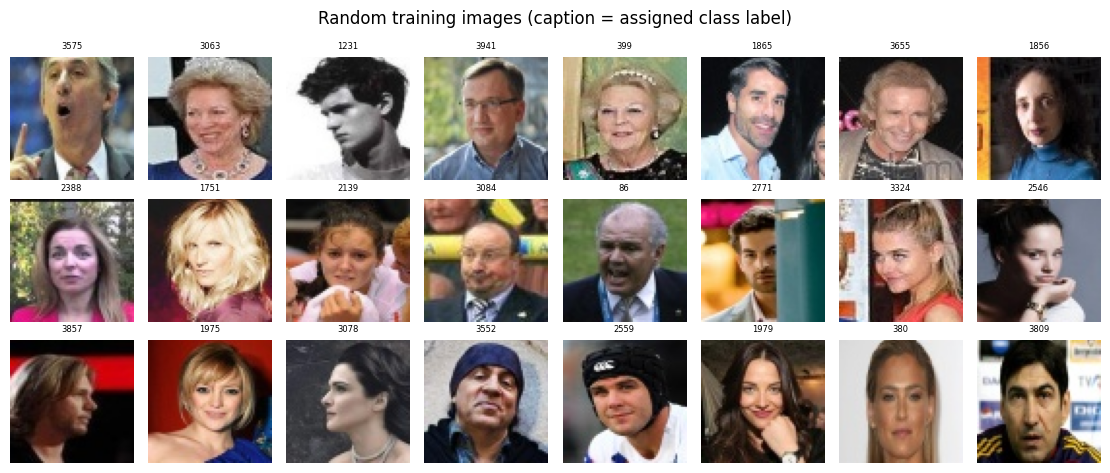

In [27]:
# CELL 27: Preview training images with their labels
sample = cls_df[cls_df.split == 'train'].sample(24, random_state=SEED)   # 24 random training images
show_grid(sample.path, 'Random training images (caption = assigned class label)',
          'A1_classification_preview', labels=sample.label)

**Explanation of Cell 27: Preview training images with their labels**

- **Purpose:** look at real images with their assigned label.
- **Output:** a grid; the number above each image is its class label.
- **Saved as:** `A1_classification_preview.png`.
- **What to check:** images are faces (not black or empty); different people have different labels.

## 1.2 Verification

`verification_data/` is a flat folder of images with no identity or train/val/test sub-folders, so there is nothing to split or label here: the notebook only lists the images and builds one table.

In [28]:
# CELL 28: List the verification images
vdir = ROOT / VERIF_DIR                      # folder with all verification images
ver_rows = []
with os.scandir(vdir) as it:
    for e in it:
        if Path(e.name).suffix.lower() in IMG_EXT:
            ver_rows.append((e.name, e.path))     # (file name, full path)
print(f'{len(ver_rows):,} verification image files found')

69,101 verification image files found


**Explanation of Cell 28: List the verification images**

- **Purpose:** collect every file in `verification_data/`.
- **Variable created:** `ver_rows` (file name, path).
- **Output:** the count (about 69,097 for the full dataset).

In [29]:
# CELL 29: Build the verification table
# One row per verification image
ver_df = pd.DataFrame(sorted(ver_rows), columns=['name', 'path'])
ver_df.insert(0, 'split', 'verification')
ver_df['ext'] = ver_df.path.str.rsplit('.', n=1).str[-1].str.lower()

ver_df.head()

,split,name,path,ext
0,verification,00000000.jpg,/content/drive/MyDrive/Facial_Recognition_with...,jpg
1,verification,00000001.jpg,/content/drive/MyDrive/Facial_Recognition_with...,jpg
2,verification,00000002.jpg,/content/drive/MyDrive/Facial_Recognition_with...,jpg
3,verification,00000003.jpg,/content/drive/MyDrive/Facial_Recognition_with...,jpg
4,verification,00000004.jpg,/content/drive/MyDrive/Facial_Recognition_with...,jpg


**Explanation of Cell 29: Build the verification table**

- **Purpose:** build `ver_df`, one row per verification image.
- **Columns:** `split` (always `verification`), `name`, `path`, `ext`.
- **Output:** the first five rows.

---
# Part B: Exploratory Data Analysis (EDA)

Part B audits the tables built in Part A. Thresholds for "blurry", "too dark" and so on are the starting values from the analysis-settings cell; confirm them with the sample grids before using them to filter data.

- **2.1 Classification**: the three splits of `classification_data`.
- **2.2 Verification**: `verification_data`.
- **2.3 Summary and handoff**: findings, report, copy to Drive.

## 2.1 Classification

### 2.1.1 Identities and images per identity

In [30]:
# CELL 30: Images per identity
# one row per (split, identity) with the number of images
per_id = cls_df.groupby(['split', 'identity']).size().rename('n_images').reset_index()
per_id.to_csv(OUT / 'images_per_identity.csv', index=False)
per_id.head()

,split,identity,n_images
0,test,n000003,2
1,test,n000010,2
2,test,n000011,2
3,test,n000013,2
4,test,n000015,2


**Explanation of Cell 30: Images per identity**

- **Purpose:** count the images of each identity in each split.
- **Variable:** `per_id` (reused by the balance and overlap cells). **File:** `images_per_identity.csv`.
- **Output:** first rows.

In [31]:
# CELL 31: Summary statistics per split
# identities, images, min / max / mean / median / std of images per identity
split_summary = per_id.groupby('split').n_images.agg(
    identities='count', images='sum', min='min', max='max',
    mean='mean', median='median', std='std').round(2).reindex(list(SPLITS))
split_summary.loc['verification', 'images'] = len(ver_df)   # verification has no identities, only a count
split_summary.to_csv(OUT / 'split_summary.csv')
split_summary

,identities,images,min,max,mean,median,std
split,,,,,,,
train,4000.0,380699.0,15.0,249.0,95.17,91.0,34.15
val,4000.0,8003.0,2.0,4.0,2.00,2.0,0.04
test,4000.0,8000.0,2.0,2.0,2.00,2.0,0.00
verification,NaN,69101.0,NaN,NaN,NaN,NaN,NaN


**Explanation of Cell 31: Summary statistics per split**

- **Purpose:** the key numbers of the dataset in one table.
- **File:** `split_summary.csv`.
- **What to check:** the minimum images per training identity decides whether triplet sampling is possible (an identity needs at least 2 images).

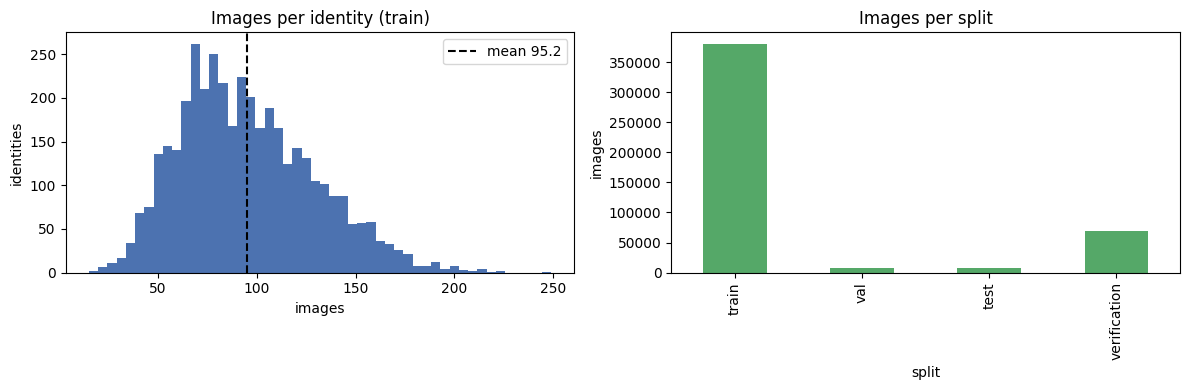

In [32]:
# CELL 32: Chart: images per identity and per split
train_counts = per_id[per_id.split == 'train'].n_images          # images per training identity
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# left: histogram of images per identity
axes[0].hist(train_counts, bins=50, color='#4C72B0')
axes[0].set(title='Images per identity (train)', xlabel='images', ylabel='identities')
axes[0].axvline(train_counts.mean(), color='k', ls='--', label=f'mean {train_counts.mean():.1f}')
axes[0].legend()
# right: images per split
split_summary['images'].plot.bar(ax=axes[1], color='#55A868')
axes[1].set(title='Images per split', ylabel='images')
savefig('B1_images_per_identity')

**Explanation of Cell 32: Chart: images per identity and per split**

- **Purpose:** show the numbers as a picture.
- **Left:** how many identities have a given number of images. A narrow peak = balanced; a long right tail = a few identities have many more images.
- **Right:** images per split.
- **Variable:** `train_counts` (used by the balance cell). **Saved as:** `B1_images_per_identity.png`.

In [33]:
# CELL 33: Identities with the fewest training images
# the 10 weakest classes
per_id[per_id.split == 'train'].nsmallest(10, 'n_images')

,split,identity,n_images
4828,train,n001967,15
5878,train,n004423,19
7632,train,n008469,20
5339,train,n003208,21
6216,train,n005193,21
7484,train,n008081,22
5280,train,n003084,23
6617,train,n006105,24
6347,train,n005521,25
4791,train,n001881,26


**Explanation of Cell 33: Identities with the fewest training images**

- **Purpose:** list the 10 training identities with the fewest images.
- **What to check:** identities with only 1 image cannot be anchors for triplet loss.

### 2.1.2 Image size, format, colour mode and quality

Every image is opened and measured (size, format, mode, brightness, contrast, sharpness, MD5 and perceptual hash).

In [34]:
# CELL 34: Scan the classification images
# Slowest cell: open the images and measure each one
q_cls = scan_many(cls_df, SCAN_FRACTION, 'scanning classification images')
q_cls.to_csv(OUT / 'image_quality_classification.csv', index=False)
print(f'scanned {len(q_cls):,} of {len(cls_df):,} images | corrupted: {int(q_cls.corrupt.sum())}')

scanning classification images:   0%|          | 0/39670 [00:00<?, ?it/s]

scanned 39,670 of 396,702 images | corrupted: 0


**Explanation of Cell 34: Scan the classification images**

- **Purpose:** measure the images (all, or a random `SCAN_FRACTION`).
- **Variable:** `q_cls` (all scanned images, including corrupted ones). **File:** `image_quality_classification.csv`.
- **Output:** progress bar, then scanned and corrupted counts.
- **Time:** minutes with a zip, much longer from Drive. If the runtime disconnects, run the cell again.

In [35]:
# CELL 35: Keep only the readable images
# ok_cls = images that could be opened; corrupted ones are reported separately
ok_cls = q_cls[~q_cls.corrupt]
bad_cls = q_cls[q_cls.corrupt]
print(f'readable: {len(ok_cls):,} | corrupted: {len(bad_cls)}')

readable: 39,670 | corrupted: 0


**Explanation of Cell 35: Keep only the readable images**

- **Purpose:** split the scan into `ok_cls` (readable, used by all charts) and `bad_cls` (corrupted).
- **Output:** the two counts.

In [36]:
# CELL 36: Function: quality_table
def quality_table(ok, bad, groups):
    # count how many images of each split fall under each quality flag
    t = ok.groupby('split').agg(
        images=('path', 'size'),
        greyscale=('is_grey', lambda s: int(s.fillna(False).sum())),
        low_res=('short_side', lambda s: int((s < LOW_RES_PX).sum())),
        blurry=('blur', lambda s: int((s < BLUR_THR).sum())),
        too_dark=('brightness', lambda s: int((s < DARK).sum())),
        too_bright=('brightness', lambda s: int((s > BRIGHT).sum())),
        low_contrast=('contrast', lambda s: int((s < LOW_CONTRAST).sum())),
    )
    # corrupted images come from the separate table
    t.insert(1, 'corrupted', bad.groupby('split').size().reindex(t.index).fillna(0).astype(int))
    return t.reindex(groups).fillna(0).astype(int)

**Explanation of Cell 36: Function: quality_table**

- **Purpose:** count, per split, the images under each quality flag: corrupted, greyscale, low-resolution, blurry, too dark, too bright, low-contrast (thresholds from the settings cell).
- **Arguments:** `ok` readable images, `bad` corrupted images, `groups` split names in display order.
- **Output:** none (defines the function only).

In [37]:
# CELL 37: Image sizes, formats and colour modes
# most common sizes per split
size_counts = (ok_cls.assign(size=ok_cls.width.astype(int).astype(str) + 'x' + ok_cls.height.astype(int).astype(str))
                     .groupby(['split', 'size']).size().rename('images').reset_index()
                     .sort_values('images', ascending=False))
# file format + colour mode per split
fmt_mode = ok_cls.groupby(['split', 'format', 'mode']).size().rename('images').reset_index()
size_counts.to_csv(OUT / 'image_sizes_classification.csv', index=False)
fmt_mode.to_csv(OUT / 'formats_and_modes_classification.csv', index=False)

display(size_counts.head(10))
fmt_mode

,split,size,images
1,train,64x64,38067
0,test,64x64,816
2,val,64x64,787


,split,format,mode,images
0,test,JPEG,RGB,816
1,train,JPEG,RGB,38067
2,val,JPEG,RGB,787


**Explanation of Cell 37: Image sizes, formats and colour modes**

- **Purpose:** find which sizes, formats and colour modes exist.
- **Output:** two tables (expect one size 64x64 and JPEG RGB).
- **Variables:** `size_counts`, `fmt_mode`. **Files:** `image_sizes_classification.csv`, `formats_and_modes_classification.csv`.
- **What to check:** several sizes mean preprocessing must resize everything to one CNN input size.

In [38]:
# CELL 38: Quality flags per split
quality_cls = quality_table(ok_cls, bad_cls, list(SPLITS))
quality_cls.to_csv(OUT / 'quality_flags_classification.csv')
# list of exactly which files could not be read
bad_cls[['split', 'path', 'error']].to_csv(OUT / 'corrupted_files_classification.csv', index=False)
quality_cls

,images,corrupted,greyscale,low_res,blurry,too_dark,too_bright,low_contrast
split,,,,,,,,
train,38067,0,411,0,2,2646,236,90
val,787,0,6,0,0,56,4,4
test,816,0,13,0,0,50,7,0


**Explanation of Cell 38: Quality flags per split**

- **Purpose:** the quality table per split.
- **Files:** `quality_flags_classification.csv`, `corrupted_files_classification.csv`.
- **How to read it:** a flag is a **warning, not an instruction to delete**. Look at the sample grids before removing images.

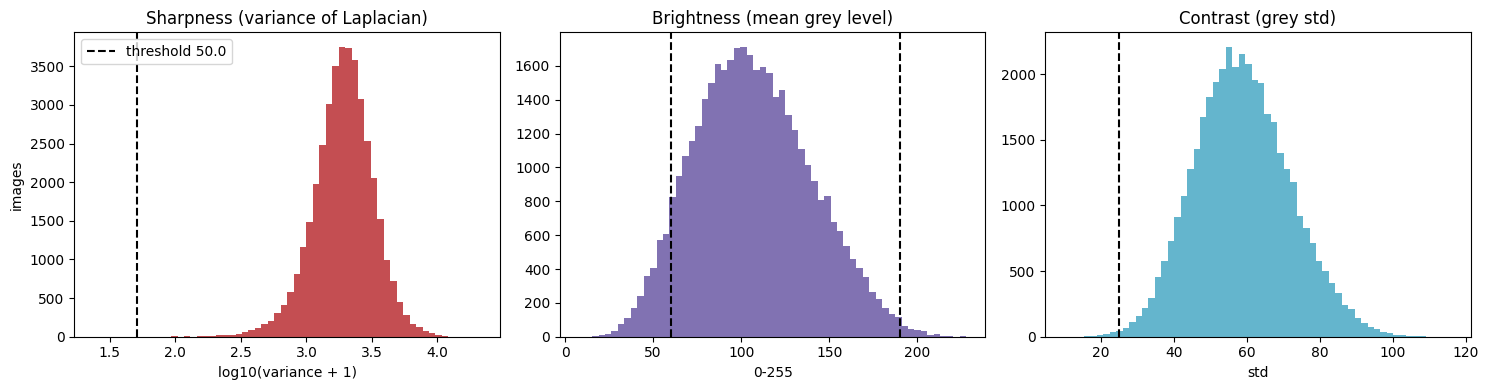

sharpness percentiles: {0.01: 452.3, 0.05: 786.7, 0.25: 1401.9, 0.5: 1951.3}


In [39]:
# CELL 39: Charts: sharpness, brightness and contrast
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# sharpness on a log scale; left of the dashed line = flagged blurry
axes[0].hist(np.log10(ok_cls.blur + 1), bins=60, color='#C44E52')
axes[0].axvline(np.log10(BLUR_THR + 1), color='k', ls='--', label=f'threshold {BLUR_THR}')
axes[0].set(title='Sharpness (variance of Laplacian)', xlabel='log10(variance + 1)', ylabel='images')
axes[0].legend()
# brightness; outside the two dashed lines = too dark / too bright
axes[1].hist(ok_cls.brightness, bins=60, color='#8172B2')
for t in (DARK, BRIGHT):
    axes[1].axvline(t, color='k', ls='--')
axes[1].set(title='Brightness (mean grey level)', xlabel='0-255')
# contrast; left of the dashed line = low contrast
axes[2].hist(ok_cls.contrast, bins=60, color='#64B5CD')
axes[2].axvline(LOW_CONTRAST, color='k', ls='--')
axes[2].set(title='Contrast (grey std)', xlabel='std')
savefig('B2_quality_distributions')

# low percentiles of sharpness, quoted in the summary
blur_pct = ok_cls.blur.quantile([0.01, 0.05, 0.25, 0.5]).round(1)
print('sharpness percentiles:', blur_pct.to_dict())

**Explanation of Cell 39: Charts: sharpness, brightness and contrast**

- **Purpose:** show where the thresholds sit in the real distributions.
- **What to check:** a threshold inside a big peak would flag half the dataset; it should sit in the low tail.
- **Variable:** `blur_pct`. **Saved as:** `B2_quality_distributions.png`.

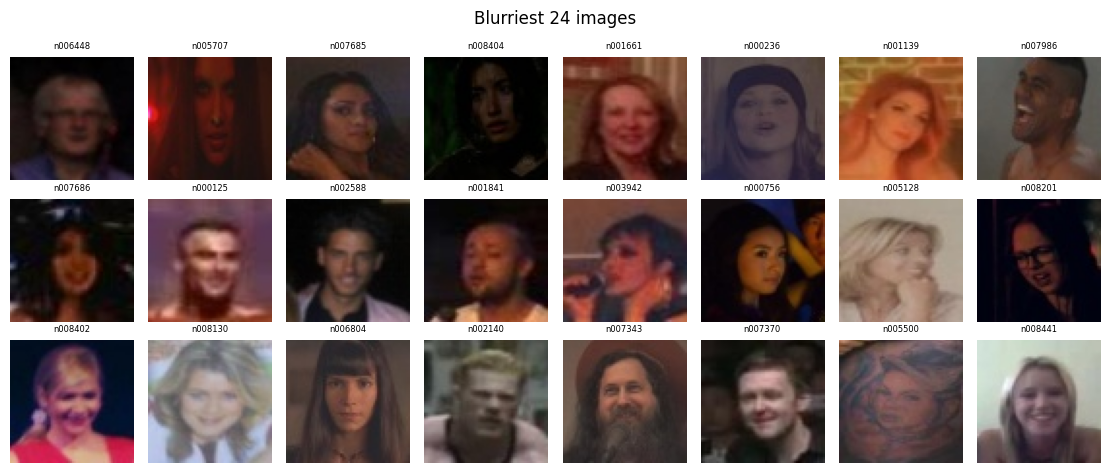

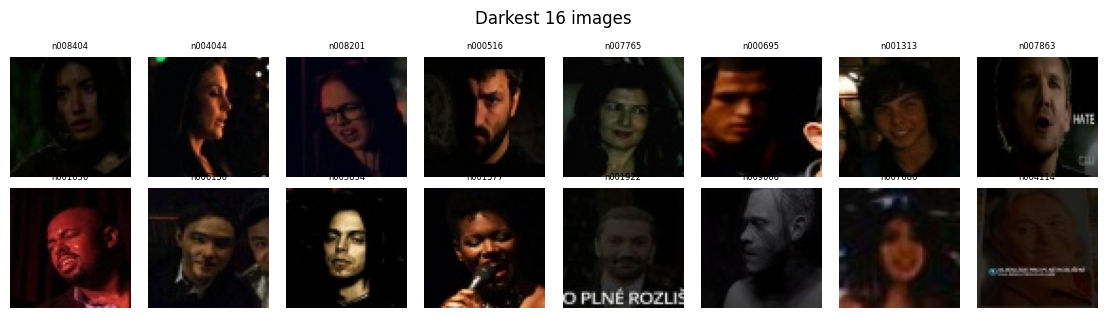

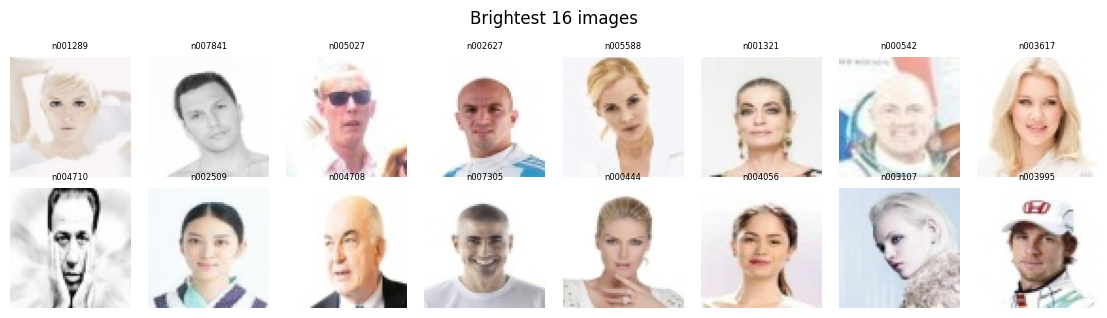

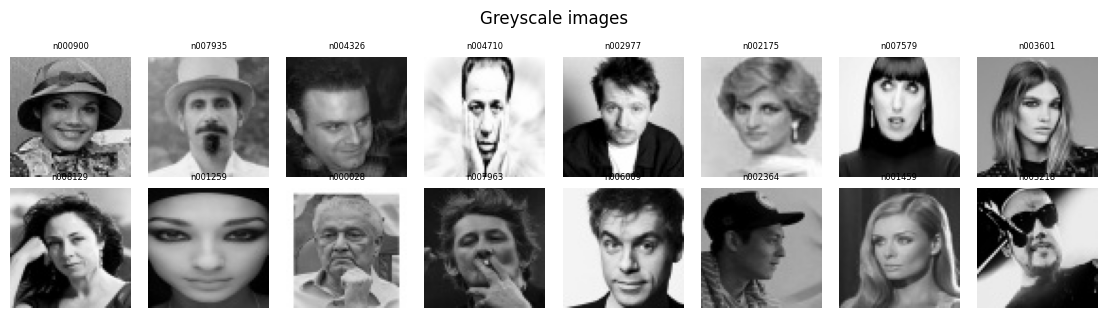

In [40]:
# CELL 40: Sample grids of the extreme images
# look at the extremes: a number cannot tell if a "dark" image is still a usable face
show_grid(ok_cls.nsmallest(24, 'blur').path, 'Blurriest 24 images', 'B2_grid_blurriest')
show_grid(ok_cls.nsmallest(16, 'brightness').path, 'Darkest 16 images', 'B2_grid_darkest')
show_grid(ok_cls.nlargest(16, 'brightness').path, 'Brightest 16 images', 'B2_grid_brightest')
show_grid(ok_cls[ok_cls.is_grey == True].path.head(16), 'Greyscale images', 'B2_grid_greyscale')

**Explanation of Cell 40: Sample grids of the extreme images**

- **Purpose:** inspect the extreme images by eye.
- **What to check:** if the blurriest images are still recognisable faces, the blur threshold may be too strict. Write the decision down for the team.
- **Saved as:** `B2_grid_blurriest.png`, `B2_grid_darkest.png`, `B2_grid_brightest.png`, `B2_grid_greyscale.png`.

### 2.1.3 Duplicates

- **Exact duplicates**: identical file bytes (same MD5).
- **Near duplicates**: identical perceptual hash (pHash).

Copies inside one identity are usually harmless. The same picture under **different identities** suggests label noise; the same picture **across splits** is leakage.

In [41]:
# CELL 41: Function: dup_groups
def dup_groups(df, key):
    # keep only rows whose hash appears more than once
    sizes = df.groupby(key).path.transform('size')
    d = df[sizes > 1].copy()
    if d.empty:
        return d.assign(group_type=pd.Series(dtype=str))
    # how many splits / identities does each duplicate group touch?
    agg = d.groupby(key).agg(n_splits=('split', 'nunique'), n_ids=('identity', 'nunique'))
    d = d.join(agg, on=key)
    d['group_type'] = np.select(
        [d.n_splits > 1, d.n_ids > 1],
        ['across splits', 'same split, different identity'],
        'same identity')
    return d.sort_values([key, 'split'])

**Explanation of Cell 41: Function: dup_groups**

- **Purpose:** find images sharing a hash and label each group:
  - `same identity`: copies in one person's folder, usually harmless;
  - `same split, different identity`: likely a **labelling error**;
  - `across splits`: **data leakage**.
- **Arguments:** `df` scanned images, `key` = `'md5'` or `'phash'`.
- **Output:** none (defines the function only).

In [42]:
# CELL 42: Find exact duplicates
exact = dup_groups(ok_cls, 'md5')                         # identical files
exact.to_csv(OUT / 'duplicates_exact.csv', index=False)
print(f'{len(exact):,} images belong to {exact.md5.nunique() if len(exact) else 0} exact-duplicate groups')

3 images belong to 1 exact-duplicate groups


**Explanation of Cell 42: Find exact duplicates**

- **Purpose:** find identical files (same MD5).
- **Variable:** `exact`. **File:** `duplicates_exact.csv` (every image in a duplicate group, so the team can open them).

In [43]:
# CELL 43: Find near duplicates
# search only images that are NOT already exact duplicates, so nothing is counted twice
near = dup_groups(ok_cls[~ok_cls.md5.isin(exact.md5)], 'phash')
near.to_csv(OUT / 'duplicates_near.csv', index=False)
print(f'{len(near):,} images belong to {near.phash.nunique() if len(near) else 0} near-duplicate groups')

16 images belong to 8 near-duplicate groups


**Explanation of Cell 43: Find near duplicates**

- **Purpose:** find re-encoded or resized copies (same pHash).
- **Variable:** `near`. **File:** `duplicates_near.csv`.

In [44]:
# CELL 44: Duplicate summary table
dup_summary = pd.DataFrame({
    'exact (md5)': exact.groupby('group_type').md5.nunique() if len(exact) else pd.Series(dtype=int),
    'near (pHash)': near.groupby('group_type').phash.nunique() if len(near) else pd.Series(dtype=int),
}).fillna(0).astype(int)
dup_summary.index.name = 'duplicate groups'
dup_summary.to_csv(OUT / 'duplicate_summary.csv')
dup_summary

,exact (md5),near (pHash)
duplicate groups,,
same identity,1,8


**Explanation of Cell 44: Duplicate summary table**

- **Purpose:** number of duplicate groups of each type.
- **What to check:** the `across splits` row should be 0; otherwise val/test contain pictures seen in training and accuracy looks better than it is.
- **Note:** with `SCAN_FRACTION` below 1 the real numbers are higher.

### 2.1.4 Coverage of lighting, pose and expression

There are **no labels** for lighting, pose, age or expression, so they are estimated: lighting from brightness (every scanned image), pose and expression from MediaPipe landmarks (a random sample). Age and demographics are not inferred; check them visually (section 2.1.5) and report them as a limitation.

In [45]:
# CELL 45: Function: light_bin
def light_bin(b):
    # brightness -> dark / normal / bright (thresholds from the settings cell)
    return 'dark' if b < DARK else ('bright' if b > BRIGHT else 'normal')

**Explanation of Cell 45: Function: light_bin**

- **Purpose:** turn a brightness value into `dark`, `normal` or `bright`.
- **Output:** none (defines the function only).

In [46]:
# CELL 46: Lighting share per split
ok_cls = ok_cls.assign(lighting=ok_cls.brightness.map(light_bin))     # new column
lighting = (pd.crosstab(ok_cls.split, ok_cls.lighting, normalize='index') * 100).round(1)   # % per split
lighting = lighting.reindex(columns=['dark', 'normal', 'bright'], fill_value=0)
lighting.to_csv(OUT / 'lighting_share_pct.csv')
lighting

lighting,dark,normal,bright
split,,,
test,6.1,93.0,0.9
train,7.0,92.4,0.6
val,7.1,92.4,0.5


**Explanation of Cell 46: Lighting share per split**

- **Purpose:** percentage of dark / normal / bright images in each split. Each row sums to 100.
- **File:** `lighting_share_pct.csv`.
- **What to check:** the splits should be similar; a much darker test set would lower accuracy for reasons unrelated to the model.

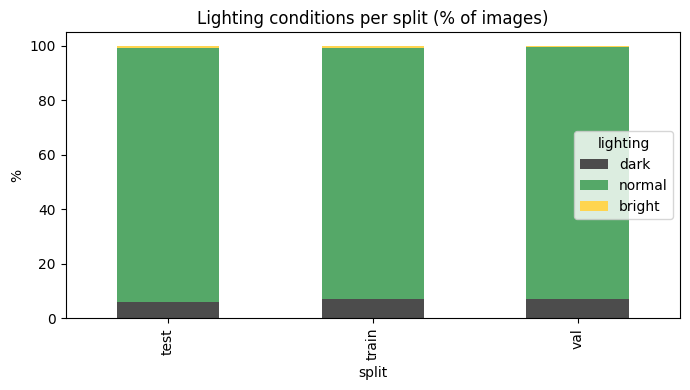

In [47]:
# CELL 47: Chart: lighting per split
lighting.plot.bar(stacked=True, figsize=(7, 4), color=['#4C4C4C', '#55A868', '#FFD54F'],
                  title='Lighting conditions per split (% of images)')
plt.ylabel('%')
savefig('B3_lighting_per_split')

**Explanation of Cell 47: Chart: lighting per split**

- **Purpose:** the lighting table as stacked bars (dark grey, normal green, bright yellow).
- **Saved as:** `B3_lighting_per_split.png`.

In [48]:
# CELL 48: Load the MediaPipe face model
landmarker = None          # stays None if anything below fails; later pose cells then skip themselves
try:
    import urllib.request
    import mediapipe as mp
    from mediapipe.tasks import python as mp_python
    from mediapipe.tasks.python import vision

    # download the face-landmark model once (about 4 MB)
    model_path = 'face_landmarker.task'
    if not Path(model_path).exists():
        urllib.request.urlretrieve(
            'https://storage.googleapis.com/mediapipe-models/face_landmarker/'
            'face_landmarker/float16/1/face_landmarker.task', model_path)

    # ask the model for blendshapes (expression scores) and a head-pose matrix
    options = vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=model_path),
        running_mode=vision.RunningMode.IMAGE, num_faces=1,
        output_face_blendshapes=True, output_facial_transformation_matrixes=True)
    landmarker = vision.FaceLandmarker.create_from_options(options)
    print('MediaPipe model loaded')
except Exception as e:
    print('pose/expression step skipped:', type(e).__name__, e)

MediaPipe model loaded


**Explanation of Cell 48: Load the MediaPipe face model**

- **Purpose:** load Google's *Face Landmarker* model. It finds facial landmarks, a head-pose matrix and expression scores.
- **Variable:** `landmarker` (`None` if loading failed).
- **Safe to fail:** the whole cell is in `try`. If MediaPipe or the download fails it prints a message and the pose cells are skipped; the rest of the notebook is unaffected.

In [49]:
# CELL 49: Run pose and expression on a sample
pose_df = None
if landmarker is not None:
    train_ok = ok_cls[ok_cls.split == 'train']
    sample = train_ok.sample(min(N_POSE_SAMPLE, len(train_ok)), random_state=SEED)   # random training sample
    out = []
    for p in tqdm(sample.path, desc='pose and expression'):
        rgb = np.asarray(Image.open(p).convert('RGB'))
        rgb = cv2.resize(rgb, (256, 256), interpolation=cv2.INTER_CUBIC)   # small faces are detected better enlarged
        res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb)))
        if not res.facial_transformation_matrixes:                         # no face found
            out.append({'path': p, 'detected': False})
            continue
        R = np.array(res.facial_transformation_matrixes[0])[:3, :3]        # rotation matrix of the head
        bs = {c.category_name: c.score for c in res.face_blendshapes[0]}   # expression scores
        out.append({
            'path': p, 'detected': True,
            'yaw': math.degrees(math.asin(float(np.clip(-R[2, 0], -1, 1)))),   # turn left / right
            'pitch': math.degrees(math.atan2(R[2, 1], R[2, 2])),               # look up / down
            'smile': (bs.get('mouthSmileLeft', 0) + bs.get('mouthSmileRight', 0)) / 2,
            'jaw_open': bs.get('jawOpen', 0),
            'frown': (bs.get('browDownLeft', 0) + bs.get('browDownRight', 0)) / 2,
        })
    pose_df = pd.DataFrame(out)
    pose_df.to_csv(OUT / 'pose_expression_sample.csv', index=False)
    print(f'processed {len(pose_df)} images, faces found: {int(pose_df.detected.sum())}')
else:
    print('skipped (MediaPipe not loaded)')

pose and expression:   0%|          | 0/3000 [00:00<?, ?it/s]

processed 3000 images, faces found: 2875


**Explanation of Cell 49: Run pose and expression on a sample**

- **Purpose:** estimate **yaw** (turn), **pitch** (up/down) and three expression scores (**smile**, **jaw open**, **frown**) for a random sample of training images.
- **Variable:** `pose_df` (`detected = False` when no face was found). **File:** `pose_expression_sample.csv`.
- **What to check:** the share of faces found. A low share on 64x64 images is a limit of this estimate, not an error in the data.

In [50]:
# CELL 50: Pose and expression summary
pose_summary = expr_summary = None
if pose_df is not None and pose_df.detected.any():
    det = pose_df[pose_df.detected].copy()
    # pose group from the absolute yaw angle
    det['pose'] = pd.cut(det.yaw.abs(), [0, 15, 35, 180],
                         labels=['frontal (<15°)', 'semi-profile (15-35°)', 'profile (>35°)'], include_lowest=True)
    # rough expression group from the blendshape scores
    det['expression'] = np.select(
        [det.smile > 0.5, det.jaw_open > 0.4, det.frown > 0.4],
        ['smiling', 'mouth open', 'frowning'], 'neutral / other')
    pose_summary = (det.pose.value_counts(normalize=True) * 100).round(1).rename('% of detected faces')
    expr_summary = (det.expression.value_counts(normalize=True) * 100).round(1).rename('% of detected faces')
    pd.concat([pose_summary, expr_summary]).to_csv(OUT / 'pose_expression_share_pct.csv')
    print(f'face landmarks found on {pose_df.detected.mean() * 100:.1f}% of the {len(pose_df)} sampled images')
    display(pose_summary); display(expr_summary)
else:
    print('No pose or expression results (the MediaPipe step was skipped or found no faces).')

face landmarks found on 95.8% of the 3000 sampled images


,% of detected faces
pose,
frontal (<15°),62.9
semi-profile (15-35°),29.3
profile (>35°),7.8


,% of detected faces
expression,
neutral / other,53.5
smiling,30.2
frowning,14.6
mouth open,1.7


**Explanation of Cell 50: Pose and expression summary**

- **Purpose:** turn raw angles and scores into shares.
- **Pose groups:** frontal (< 15°), semi-profile (15–35°), profile (> 35°). **Expression groups:** smiling, mouth open, frowning, neutral/other (rough thresholds: treat as a hint).
- **Variables:** `det`, `pose_summary`, `expr_summary`. **File:** `pose_expression_share_pct.csv`.
- **If MediaPipe was skipped:** prints a message and does nothing.

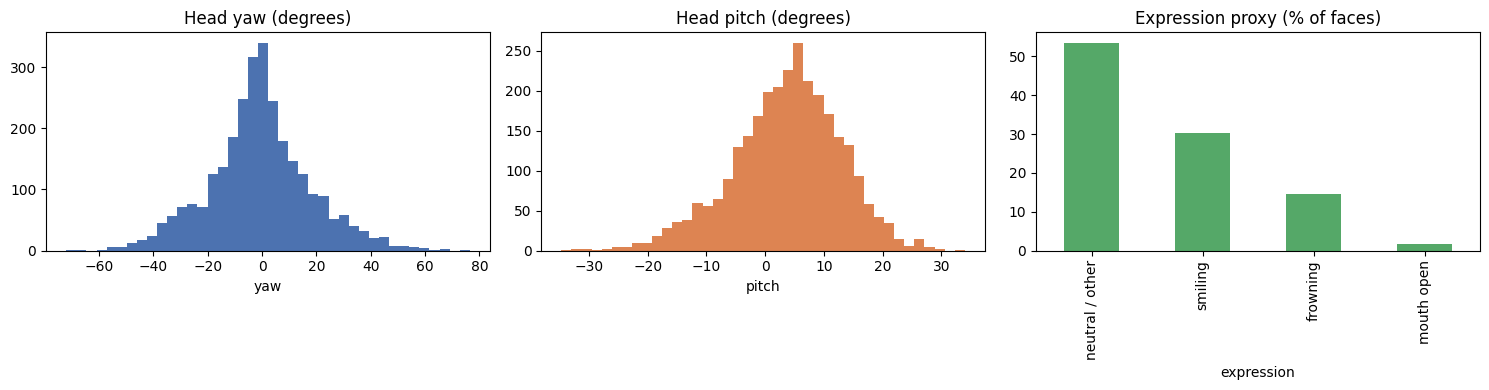

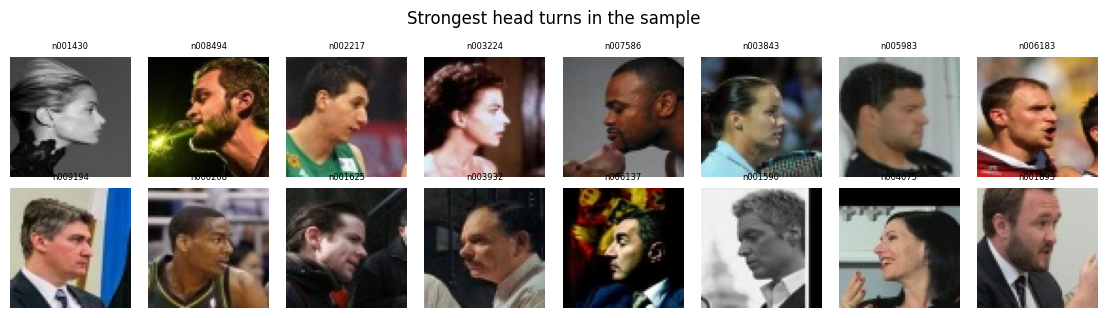

In [51]:
# CELL 51: Pose and expression charts
if pose_summary is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].hist(det.yaw, bins=40, color='#4C72B0');   axes[0].set(title='Head yaw (degrees)', xlabel='yaw')
    axes[1].hist(det.pitch, bins=40, color='#DD8452'); axes[1].set(title='Head pitch (degrees)', xlabel='pitch')
    expr_summary.plot.bar(ax=axes[2], color='#55A868', title='Expression proxy (% of faces)')
    savefig('B4_pose_and_expression')
    # the strongest head turns, to check the estimate by eye
    show_grid(det.loc[det.yaw.abs().nlargest(16).index, 'path'], 'Strongest head turns in the sample', 'B4_grid_profile')
else:
    print('nothing to plot')

**Explanation of Cell 51: Pose and expression charts**

- **Purpose:** histograms of yaw and pitch, a bar chart of expressions, and a grid of the strongest head turns.
- **Saved as:** `B4_pose_and_expression.png`, `B4_grid_profile.png`.

### 2.1.5 Identity balance

A Gini coefficient of 0 means every identity has the same number of images; values near 1 mean a few identities hold most images.

In [52]:
# CELL 52: Identity balance statistics
c = np.sort(train_counts.values)                 # images per training identity, sorted
n_id = len(c)
gini = (2 * np.arange(1, n_id + 1) - n_id - 1).dot(c) / (n_id * c.sum())   # Gini coefficient
top10_share = c[-max(1, n_id // 10):].sum() / c.sum() * 100                # % of images in the top 10% identities
balance = pd.Series({
    'identities (train)': n_id,
    'images per identity: min': c.min(),
    'images per identity: max': c.max(),
    'images per identity: mean': round(c.mean(), 2),
    'coefficient of variation': round(c.std() / c.mean(), 3),
    'Gini coefficient (0 = perfectly even)': round(gini, 3),
    '% of images held by the top 10% of identities': round(top10_share, 1),
    'identities with < 10 images': int((c < 10).sum()),
    'identities with < 2 images': int((c < 2).sum()),
}, name='value')
balance.to_csv(OUT / 'identity_balance.csv')
balance

,value
identities (train),4000.000
images per identity: min,15.000
images per identity: max,249.000
images per identity: mean,95.170
coefficient of variation,0.359
Gini coefficient (0 = perfectly even),0.202
% of images held by the top 10% of identities,17.000
identities with < 10 images,0.000
identities with < 2 images,0.000


**Explanation of Cell 52: Identity balance statistics**

- **Purpose:** measure how balanced the training set is.
- **Measures:** coefficient of variation (std / mean), Gini, share of data in the top 10% of identities (a perfectly even set gives 10%), and counts of weak identities (< 10 and < 2 images).
- **Variable / file:** `balance`, `identity_balance.csv`.
- **What to check:** high Gini or top-10% share means frequent identities may be learned better; mention it in the report.

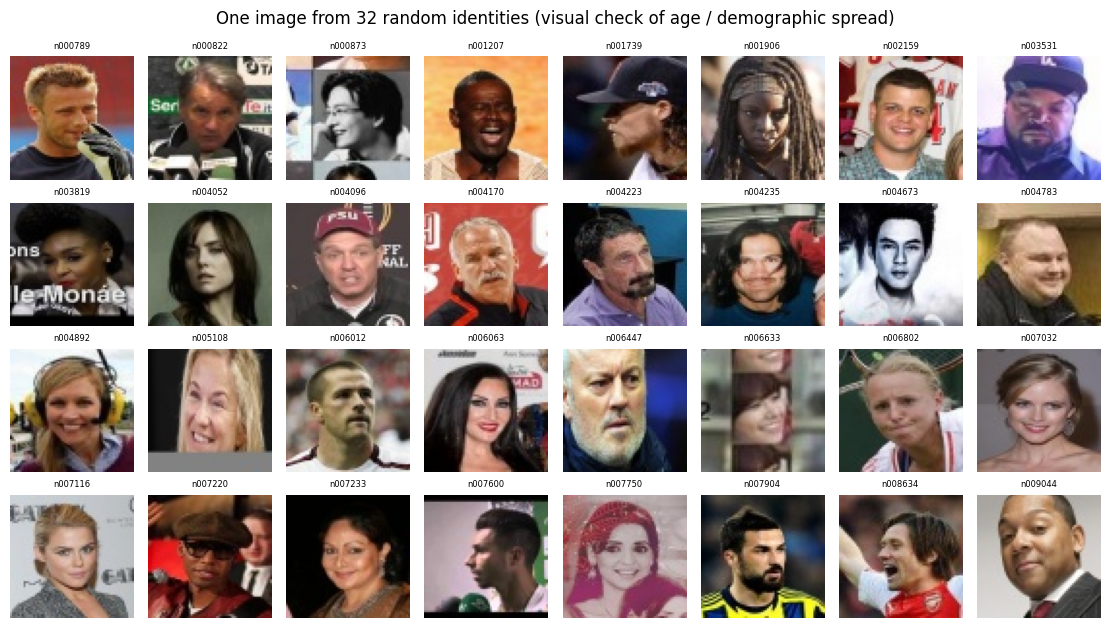

In [53]:
# CELL 53: Grid: one image from random identities
rng = np.random.default_rng(SEED)
# pick up to 32 random training identities
ids = rng.choice(per_id[per_id.split == 'train'].identity.unique(), size=min(32, n_id), replace=False)
# first image of each chosen identity
first_imgs = cls_df[(cls_df.split == 'train') & cls_df.identity.isin(ids)].groupby('identity').path.first()
show_grid(first_imgs, 'One image from 32 random identities (visual check of age / demographic spread)',
          'B5_grid_random_identities')

**Explanation of Cell 53: Grid: one image from random identities**

- **Purpose:** age and demographics are not labelled, so judge them by looking.
- **What to check:** is there a visible mix of ages, genders and skin tones, or does one group dominate? Report it as a limitation; do not guess attributes of individuals.
- **Saved as:** `B5_grid_random_identities.png`.

### 2.1.6 Data leakage between the classification splits

- **Identity overlap**: `val_data` and `test_data` measure *classification* accuracy, so they contain the **same people** as train (closed-set). That is by design.
- **Image overlap**: the same picture (MD5) or a near copy (pHash) in two splits *is* leakage.

In [54]:
# CELL 54: Identity overlap between splits
id_sets = {s: set(per_id[per_id.split == s].identity) for s in SPLITS}      # identities of each split
pair_list = [('train', 'val'), ('train', 'test'), ('val', 'test')]
id_overlap = pd.DataFrame([{
    'split A': a, 'split B': b,
    'identities A': len(id_sets[a]), 'identities B': len(id_sets[b]),
    'shared identities': len(id_sets[a] & id_sets[b]),
    '% of B also in A': round(len(id_sets[a] & id_sets[b]) / max(1, len(id_sets[b])) * 100, 1),
} for a, b in pair_list])
id_overlap.to_csv(OUT / 'leakage_identity_overlap.csv', index=False)
id_overlap

,split A,split B,identities A,identities B,shared identities,% of B also in A
0,train,val,4000,4000,4000,100.0
1,train,test,4000,4000,4000,100.0
2,val,test,4000,4000,4000,100.0


**Explanation of Cell 54: Identity overlap between splits**

- **Purpose:** which people appear in more than one split.
- **How to read it:** 100% sharing is **correct** here (closed-set classification). It would be a problem only for verification, where test people should be unseen.
- **File:** `leakage_identity_overlap.csv`.

In [55]:
# CELL 55: Function: overlap_matrix
def overlap_matrix(df, key, groups):
    # for every pair of groups, count how many hashes (images) they share
    sets = {s: set(df[df.split == s][key]) for s in groups}
    return pd.DataFrame([[len(sets[a] & sets[b]) if a != b else np.nan for b in groups] for a in groups],
                        index=groups, columns=groups)

**Explanation of Cell 55: Function: overlap_matrix**

- **Purpose:** count how many images two splits have in common.
- **Arguments:** `df` scanned images, `key` = `'md5'` or `'phash'`, `groups` split names.
- **Returns:** a square table; the diagonal is empty.
- **Output:** none (defines the function only).

In [56]:
# CELL 56: Identical images shared between splits (MD5)
cls_groups = list(SPLITS)
leak_exact_cls = overlap_matrix(ok_cls, 'md5', cls_groups)
leak_exact_cls.to_csv(OUT / 'leakage_exact_image_overlap_classification.csv')
leak_exact_cls

,train,val,test
train,NaN,0.0,0.0
val,0.0,NaN,0.0
test,0.0,0.0,NaN


**Explanation of Cell 56: Identical images shared between splits (MD5)**

- **Purpose:** do train, val and test share any identical picture?
- **What to check:** every number should be **0**. A positive number is leakage; open `duplicates_exact.csv` to find the files.
- **File:** `leakage_exact_image_overlap_classification.csv`.

In [57]:
# CELL 57: Near-identical images shared between splits (pHash)
leak_near_cls = overlap_matrix(ok_cls, 'phash', cls_groups)
leak_near_cls.to_csv(OUT / 'leakage_near_image_overlap_classification.csv')
leak_near_cls

,train,val,test
train,NaN,0.0,0.0
val,0.0,NaN,0.0
test,0.0,0.0,NaN


**Explanation of Cell 57: Near-identical images shared between splits (pHash)**

- **Purpose:** the same check for near copies (includes the identical ones).
- **What to check:** numbers should be 0 or very small. See `duplicates_near.csv` for the files.
- **File:** `leakage_near_image_overlap_classification.csv`.

## 2.2 Verification

### 2.2.1 Verification images: size, format and quality

In [58]:
# CELL 58: Scan the verification images
q_ver = scan_many(ver_df, SCAN_FRACTION, 'scanning verification images')    # same measurement as for training
q_ver.to_csv(OUT / 'image_quality_verification.csv', index=False)
ok_ver = q_ver[~q_ver.corrupt]                                              # readable ones
print(f'scanned {len(q_ver):,} of {len(ver_df):,} verification images | corrupted: {int(q_ver.corrupt.sum())}')

scanning verification images:   0%|          | 0/6910 [00:00<?, ?it/s]

scanned 6,910 of 69,101 verification images | corrupted: 0


**Explanation of Cell 58: Scan the verification images**

- **Purpose:** measure the verification images exactly like the training images.
- **Variables:** `q_ver` (all), `ok_ver` (readable). **File:** `image_quality_verification.csv`.

In [59]:
# CELL 59: Verification image sizes and formats
# size, format and colour mode of the verification images
ok_ver.assign(size=ok_ver.width.astype(int).astype(str) + 'x' + ok_ver.height.astype(int).astype(str)) \
      .groupby(['size', 'format', 'mode']).size().rename('images').reset_index()

,size,format,mode,images
0,64x64,JPEG,RGB,6910


**Explanation of Cell 59: Verification image sizes and formats**

- **Purpose:** check that verification images match the training images.
- **What to check:** size and mode must equal the training ones (64x64 JPEG RGB). A different size makes scores unreliable unless images are resized the same way.

In [60]:
# CELL 60: Verification quality flags
quality_ver = quality_table(ok_ver, q_ver[q_ver.corrupt], ['verification'])
quality_ver.to_csv(OUT / 'quality_flags_verification.csv')
quality_ver

,images,corrupted,greyscale,low_res,blurry,too_dark,too_bright,low_contrast
split,,,,,,,,
verification,6910,0,67,0,0,455,42,20


**Explanation of Cell 60: Verification quality flags**

- **Purpose:** quality flags for the verification set, using the same thresholds.
- **File:** `quality_flags_verification.csv`.

### 2.2.2 Leakage: verification images against the training data

Verification images should not be pictures the models already saw in `train_data`; otherwise AUC and the threshold are too optimistic.

In [61]:
# CELL 61: Combine classification and verification scans
q_all = pd.concat([q_cls, q_ver], ignore_index=True)            # all scanned images together
ok_all = q_all[~q_all.corrupt]
all_groups = list(SPLITS) + ['verification']
print(f'{len(ok_all):,} readable images in {len(all_groups)} groups')

46,580 readable images in 4 groups


**Explanation of Cell 61: Combine classification and verification scans**

- **Purpose:** put train, val, test and verification in one table so they can be compared.
- **Variables:** `ok_all`, `all_groups`.

In [62]:
# CELL 62: Identical images shared, including verification (MD5)
leak_exact = overlap_matrix(ok_all, 'md5', all_groups)
leak_exact.to_csv(OUT / 'leakage_exact_image_overlap.csv')
leak_exact

,train,val,test,verification
train,NaN,0.0,0.0,73.0
val,0.0,NaN,0.0,1.0
test,0.0,0.0,NaN,0.0
verification,73.0,1.0,0.0,NaN


**Explanation of Cell 62: Identical images shared, including verification (MD5)**

- **Purpose:** the leakage matrix with a fourth group, `verification`.
- **What to check:** the `train` / `verification` cell. A positive number means verification images also appear in training, so the AUC is too optimistic.
- **File:** `leakage_exact_image_overlap.csv`.

In [63]:
# CELL 63: Near-identical images shared, including verification (pHash)
leak_near = overlap_matrix(ok_all, 'phash', all_groups)
leak_near.to_csv(OUT / 'leakage_near_image_overlap.csv')
leak_near

,train,val,test,verification
train,NaN,0.0,0.0,74.0
val,0.0,NaN,0.0,1.0
test,0.0,0.0,NaN,0.0
verification,74.0,1.0,0.0,NaN


**Explanation of Cell 63: Near-identical images shared, including verification (pHash)**

- **Purpose:** the same matrix for near copies.
- **Note:** with `SCAN_FRACTION` below 1 only scanned images are compared, so real overlap is larger.
- **File:** `leakage_near_image_overlap.csv`.

In [64]:
# CELL 64: Verification images found in the training data
train_md5 = set(ok_cls[ok_cls.split == 'train'].md5)             # hashes of all training images
ver_in_train = ok_ver[ok_ver.md5.isin(train_md5)]                # verification images found in training
leak_rows = [{'what': 'verification images identical to a training image',
              'count': len(ver_in_train), '% of scanned': round(len(ver_in_train) / max(1, len(ok_ver)) * 100, 2)}]
verif_leak = pd.DataFrame(leak_rows)
verif_leak.to_csv(OUT / 'leakage_verification_vs_train.csv', index=False)
verif_leak

,what,count,% of scanned
0,verification images identical to a training image,73,1.06


**Explanation of Cell 64: Verification images found in the training data**

- **Purpose:** count the verification images that are also in `train_data` (identical file, MD5).
- **What to do with it:** the team decides whether to drop those images from evaluation or remove them from training. Do not change data without agreeing first.
- **Note:** with `SCAN_FRACTION` below 1 these are lower bounds.
- **File:** `leakage_verification_vs_train.csv`.

### 2.2.3 Visual check of the verification images

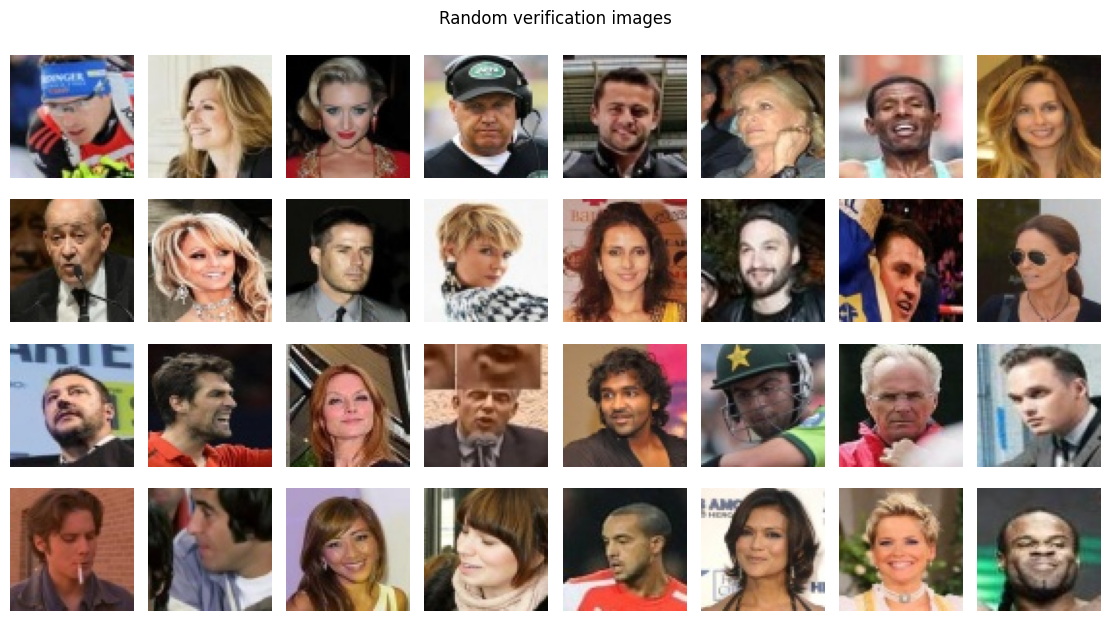

In [65]:
# CELL 65: Grid: random verification images
n_show = min(32, len(ok_ver))
show_grid(ok_ver.sample(n_show, random_state=SEED).path, 'Random verification images',
          'B7_grid_verification_images', labels=[''] * n_show)

**Explanation of Cell 65: Grid: random verification images**

- **Purpose:** look at the verification images, as done for training.
- **What to check:** same crop, size and style as the training faces.
- **Saved as:** `B7_grid_verification_images.png`.

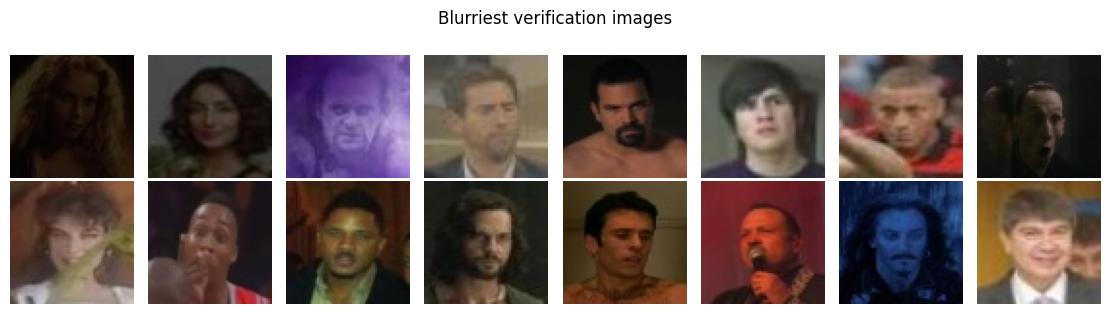

In [66]:
# CELL 66: Grid: blurriest verification images
n_blur = min(16, len(ok_ver))
show_grid(ok_ver.nsmallest(n_blur, 'blur').path, 'Blurriest verification images',
          'B7_grid_verification_blurriest', labels=[''] * n_blur)

**Explanation of Cell 66: Grid: blurriest verification images**

- **Purpose:** the worst verification images by sharpness.
- **Saved as:** `B7_grid_verification_blurriest.png`.

## 2.3 Summary and handoff

The cells below build a plain-text summary (`EDA_summary.md`), an HTML report and copy everything to Google Drive.

In [67]:
# CELL 67: Summary: dataset size
tr = split_summary.loc['train']
lines = [                                                  # `lines` collects one text line per finding
    '# Face recognition EDA: summary', '',
    '## Dataset size (classification)',
    f"- Training: {fmt_int(tr.identities)} identities, {fmt_int(tr.images)} images; "
    f"{fmt_int(tr['min'])}-{fmt_int(tr['max'])} images per identity (mean {tr['mean']:.1f}, median {tr['median']:.0f}).",
]
for s in ['val', 'test']:
    r = split_summary.loc[s]
    lines.append(f"- {s.capitalize()}: {fmt_int(r.identities)} identities, {fmt_int(r.images)} images "
                 f"({fmt_int(r['min'])}-{fmt_int(r['max'])} per identity).")
lines.append(f"- Class labels assigned: {len(label_map):,} (from train_data identities).")
print(len(lines), 'lines so far')

7 lines so far


**Explanation of Cell 67: Summary: dataset size**

- **Purpose:** start the written summary from the tables above, so nobody retypes numbers.
- **Variable:** `lines`, a list with one text line per finding. Later summary cells add to it.
- **If it fails with `NameError`:** a cell above was not run; the error names it.

In [68]:
# CELL 68: Summary: image quality and duplicates
lines += ['', '## Image properties and quality (classification)']
lines.append(f"- Scan coverage: {SCAN_FRACTION:.0%} of the images.")
top_sizes = size_counts.groupby('size').images.sum().sort_values(ascending=False).head(3)
lines.append('- Sizes: ' + ', '.join(f'{k} ({fmt_int(v)})' for k, v in top_sizes.items()) + '.')
lines.append('- Formats / modes: ' + ', '.join(f'{f} {m} ({fmt_int(c)})' for (f, m), c in
             ok_cls.groupby(['format', 'mode']).size().items()) + '.')
tot = quality_cls.sum()                                    # flags summed over all splits
lines.append(f"- Flags across all splits: {fmt_int(tot.corrupted)} corrupted, {fmt_int(tot.low_res)} low-resolution (<{LOW_RES_PX}px), "
             f"{fmt_int(tot.blurry)} blurry (Laplacian variance <{BLUR_THR}), {fmt_int(tot.too_dark)} too dark, "
             f"{fmt_int(tot.too_bright)} too bright, {fmt_int(tot.greyscale)} greyscale.")
lines.append(f"- Duplicate groups: {fmt_int(exact.md5.nunique() if len(exact) else 0)} exact, "
             f"{fmt_int(near.phash.nunique() if len(near) else 0)} near-duplicate.")
print(len(lines), 'lines so far')

14 lines so far


**Explanation of Cell 68: Summary: image quality and duplicates**

- **Purpose:** add scan coverage, sizes, formats, quality flags and duplicate groups to `lines`.

In [69]:
# CELL 69: Summary: coverage and balance
lines += ['', '## Coverage and balance (classification)']
lines.append('- Lighting (% of training images): ' + ', '.join(f'{k} {v}%' for k, v in lighting.loc['train'].items()) + '.')
if pose_summary is not None:                               # only when MediaPipe worked
    lines.append('- Head pose (sample): ' + ', '.join(f'{k} {v}%' for k, v in pose_summary.items()) + '.')
    lines.append('- Expression proxy (sample): ' + ', '.join(f'{k} {v}%' for k, v in expr_summary.items()) + '.')
else:
    lines.append('- Head pose / expression: not measured (MediaPipe step skipped).')
lines.append(f"- Identity balance: Gini {balance['Gini coefficient (0 = perfectly even)']}, top 10% of identities hold "
             f"{balance['% of images held by the top 10% of identities']}% of images; "
             f"{fmt_int(balance['identities with < 10 images'])} identities have fewer than 10 images.")
lines.append('- Age and demographics are not labelled; see B5_grid_random_identities.png for a visual check.')
print(len(lines), 'lines so far')

21 lines so far


**Explanation of Cell 69: Summary: coverage and balance**

- **Purpose:** add lighting, pose, expression and identity balance. If the MediaPipe step was skipped the summary says so.

In [70]:
# CELL 70: Summary: verification
lines += ['', '## Verification']
lines.append(f"- Verification images: {fmt_int(len(ver_df))} (scanned {fmt_int(len(q_ver))}, corrupted {fmt_int(q_ver.corrupt.sum())}).")
for _, r in verif_leak.iterrows():                         # verification vs training leakage
    lines.append(f"- {r['what']}: {fmt_int(r['count'])} ({r['% of scanned']}% of scanned).")
print(len(lines), 'lines so far')

25 lines so far


**Explanation of Cell 70: Summary: verification**

- **Purpose:** add the verification image count and the verification-vs-training leakage.

In [71]:
# CELL 71: Summary: leakage between splits
lines += ['', '## Leakage between splits']
for _, r in id_overlap.iterrows():
    lines.append(f"- {r['split A']} / {r['split B']}: {fmt_int(r['shared identities'])} shared identities (expected for closed-set classification).")
for a in all_groups:
    for b in all_groups:
        if all_groups.index(a) < all_groups.index(b):      # each pair of groups once
            e, nr = leak_exact.loc[a, b], leak_near.loc[a, b]
            if e or nr:
                lines.append(f"- {a} / {b}: {fmt_int(e)} identical images shared, {fmt_int(nr)} when near-identical copies are included (LEAKAGE).")
if not np.nansum(leak_exact.values) and not np.nansum(leak_near.values):
    lines.append('- No identical or near-identical images are shared between any splits or the verification data.')
print(len(lines), 'lines so far')

32 lines so far


**Explanation of Cell 71: Summary: leakage between splits**

- **Purpose:** add identity overlap and a line for every pair of groups that shares at least one image (or a note that nothing is shared).

In [72]:
# CELL 72: Summary: suggested rules, then write EDA_summary.md
lines += ['', '## Suggested cleaning and splitting rules (for team decision)',
          '- Remove corrupted files listed in corrupted_files_classification.csv.',
          '- Remove images from val, test and verification that also appear in train (or drop the train copy).',
          '- Review duplicates labelled "same split, different identity" as possible label noise.',
          f"- Confirm the blur threshold from B2_grid_blurriest.png (1st percentile of sharpness = {blur_pct.loc[0.01]}).",
          '- Keep the given train/val/test split; train metric learning on train_data only; verification_data is for evaluation only.',
          '- Identities with < 2 images cannot form positive pairs for triplet loss.']

summary_text = '\n'.join(lines)
(OUT / 'EDA_summary.md').write_text(summary_text, encoding='utf-8')   # save to file
print(summary_text)

# Face recognition EDA: summary

## Dataset size (classification)
- Training: 4,000 identities, 380,699 images; 15-249 images per identity (mean 95.2, median 91).
- Val: 4,000 identities, 8,003 images (2-4 per identity).
- Test: 4,000 identities, 8,000 images (2-2 per identity).
- Class labels assigned: 4,000 (from train_data identities).

## Image properties and quality (classification)
- Scan coverage: 10% of the images.
- Sizes: 64x64 (39,670).
- Formats / modes: JPEG RGB (39,670).
- Flags across all splits: 0 corrupted, 0 low-resolution (<32px), 2 blurry (Laplacian variance <50.0), 2,752 too dark, 247 too bright, 430 greyscale.
- Duplicate groups: 1 exact, 8 near-duplicate.

## Coverage and balance (classification)
- Lighting (% of training images): dark 7.0%, normal 92.4%, bright 0.6%.
- Head pose (sample): frontal (<15°) 62.9%, semi-profile (15-35°) 29.3%, profile (>35°) 7.8%.
- Expression proxy (sample): neutral / other 53.5%, smiling 30.2%, frowning 14.6%, mouth open 1.7%.
- Id

**Explanation of Cell 72: Summary: suggested rules, then write EDA_summary.md**

- **Purpose:** finish the summary, save `EDA_summary.md` and print it.
- **Suggested rules** are **proposals for the team to approve**; nothing on Drive is modified.
- **Output:** the full summary: read this first and paste it into the report.

In [73]:
# CELL 73: HTML helper: img_tag
def img_tag(name):
    p = OUT / f'{name}.png'
    if not p.exists():                       # e.g. pose chart when MediaPipe was skipped
        return ''
    b64 = base64.b64encode(p.read_bytes()).decode()      # embed the PNG as text
    return f'<img src="data:image/png;base64,{b64}" style="max-width:100%;margin:8px 0">'

**Explanation of Cell 73: HTML helper: img_tag**

- **Purpose:** embed a saved chart PNG inside the HTML (base64), so the report is a **single file**.
- **Returns:** an `<img>` tag, or an empty string if the chart does not exist.
- **Output:** none (defines the function only).

In [74]:
# CELL 74: HTML helper: table
def table(df, title):
    # heading + the pandas table as HTML
    return f'<h3>{html.escape(title)}</h3>' + df.to_html(border=0, classes='t', na_rep='-')

**Explanation of Cell 74: HTML helper: table**

- **Purpose:** turn a pandas table into an HTML table with a heading.
- **Output:** none (defines the function only).

In [75]:
# CELL 75: HTML style (css)
css = ('body{font-family:Arial,sans-serif;max-width:980px;margin:24px auto;padding:0 16px}'
       'table.t{border-collapse:collapse;font-size:13px}table.t td,table.t th{border:1px solid #ccc;padding:3px 8px}'
       'th{background:#f1f1f1}')

**Explanation of Cell 75: HTML style (css)**

- **Purpose:** the page style (font, table borders). Edit here to change how the report looks.

In [76]:
# CELL 76: Convert the summary to HTML
# "# " -> h1, "## " -> h2, "- " -> list item
summary_html = ''.join(
    f'<h2>{html.escape(l[3:])}</h2>' if l.startswith('## ') else
    f'<h1>{html.escape(l[2:])}</h1>' if l.startswith('# ') else
    f'<li>{html.escape(l[2:])}</li>' if l.startswith('- ') else ''
    for l in summary_text.splitlines())
print(len(summary_html), 'characters of HTML')

2668 characters of HTML


**Explanation of Cell 76: Convert the summary to HTML**

- **Purpose:** convert the markdown-style summary lines into HTML headings and list items.
- **Variable:** `summary_html`.

In [77]:
# CELL 77: Choose the charts for the report
# charts (saved PNG names) shown at the end of the report, in this order
charts = ['A1_classification_preview', 'B1_images_per_identity',
          'B2_quality_distributions', 'B3_lighting_per_split', 'B4_pose_and_expression', 'B5_grid_random_identities',
          'B2_grid_blurriest', 'B7_grid_verification_images']

**Explanation of Cell 77: Choose the charts for the report**

- **Purpose:** the list of charts in the report. To add a chart, save it with `savefig('name')` and add `'name'` here.

In [78]:
# CELL 78: Build the HTML report
sections = [
    summary_html,                                            # written summary first
    '<h2>Tables: classification</h2>',
    table(split_summary, 'Images and identities per split'),
    table(quality_cls, 'Quality flags per split'),
    table(fmt_mode, 'Formats and colour modes'),
    table(dup_summary, 'Duplicate groups'),
    table(lighting, 'Lighting share per split (%)'),
    table(balance.to_frame(), 'Identity balance (train)'),
    table(id_overlap, 'Identity overlap between splits'),
    '<h2>Tables: verification and leakage</h2>',
    table(quality_ver, 'Verification image quality flags'),
    table(verif_leak, 'Verification data against training'),
    table(leak_exact, 'Identical images shared between splits (MD5)'),
    table(leak_near, 'Near-identical images shared between splits (pHash)'),
    '<h2>Charts and sample images</h2>',
] + [img_tag(c) for c in charts]                             # then the charts

(OUT / 'EDA_report.html').write_text(
    f'<html><head><meta charset="utf-8"><style>{css}</style></head><body>' + ''.join(sections) + '</body></html>',
    encoding='utf-8')
print('wrote', OUT / 'EDA_report.html')

wrote eda_outputs/EDA_report.html


**Explanation of Cell 78: Build the HTML report**

- **Purpose:** assemble `EDA_report.html`: summary, then tables, then charts.
- **Output:** the report path. Open it from the Colab file browser, or from Drive after the next cell.

In [79]:
# CELL 79: Copy all outputs to Google Drive
if SAVE_TO is not None:
    SAVE_TO.mkdir(parents=True, exist_ok=True)
    for f in OUT.iterdir():
        shutil.copy(f, SAVE_TO / f.name)                    # copy every result file
    print('copied', len(list(OUT.iterdir())), 'files to', SAVE_TO)
sorted(p.name for p in OUT.iterdir())                        # list what was produced

copied 39 files to /content/drive/MyDrive/face_recognition_eda


['A1_classification_preview.png',
 'B1_images_per_identity.png',
 'B2_grid_blurriest.png',
 'B2_grid_brightest.png',
 'B2_grid_darkest.png',
 'B2_grid_greyscale.png',
 'B2_quality_distributions.png',
 'B3_lighting_per_split.png',
 'B4_grid_profile.png',
 'B4_pose_and_expression.png',
 'B5_grid_random_identities.png',
 'B7_grid_verification_blurriest.png',
 'B7_grid_verification_images.png',
 'EDA_report.html',
 'EDA_summary.md',
 'classification_inventory.csv',
 'corrupted_files_classification.csv',
 'duplicate_summary.csv',
 'duplicates_exact.csv',
 'duplicates_near.csv',
 'formats_and_modes_classification.csv',
 'identity_balance.csv',
 'image_quality_classification.csv',
 'image_quality_verification.csv',
 'image_sizes_classification.csv',
 'images_per_identity.csv',
 'label_map.csv',
 'leakage_exact_image_overlap.csv',
 'leakage_exact_image_overlap_classification.csv',
 'leakage_identity_overlap.csv',
 'leakage_near_image_overlap.csv',
 'leakage_near_image_overlap_classification.cs

**Explanation of Cell 79: Copy all outputs to Google Drive**

- **Purpose:** save the results outside Colab (files in `eda_outputs/` vanish when the session ends).
- **Where:** `My Drive/face_recognition_eda/`. Share this folder with the team.
- **Not on GitHub:** commit only this notebook (outputs cleared), never datasets or result images.

## Handoff to training

- Review `EDA_summary.md` and the leakage tables before training or choosing the verification threshold. Treat leakage and duplicate lists as proposals for the team to approve, not as changes already made.
- Remove corrupted files; drop val, test and verification images that also appear in train (or the train copy); review duplicates under different identities as possible label noise.
- Confirm the blur and lighting thresholds from the sample grids before filtering, and filter training data only, never the evaluation sets.
- Keep the given split. The classification model trains on `train_data` with labels from `label_map.csv`. The metric-learning model trains on `train_data` only; keep `verification_data` for evaluation only.
- Note in the report that age and demographics are unlabelled, and that pose and expression shares are landmark-based estimates from a sample.